# Лабораторная работа №3: Продвинутые модели ML и интерпретация

**Вариант №1** · датасет **Titanic** (`seaborn`) · задача **бинарная классификация** (таргет `survived`)

Что требуется по варианту:

1. **Базовые модели** — три библиотеки градиентного бустинга (**XGBoost, LightGBM, CatBoost**) с
   параметрами по умолчанию; сравнить качество (ROC-AUC на 5 фолдах) и время обучения, выбрать лучшую.
2. **Оптимизация гиперпараметров** — **Optuna** (не менее 50 trials) с фиксацией `random_state`,
   CV внутри objective; зафиксировать лучшие параметры и метрику.
3. **Интерпретация** — **SHAP**: `summary`, `dependence` (для двух важнейших признаков) и др.
4. **Стекинг** — `StackingClassifier` из **LightGBM + RandomForest + LogisticRegression**, `cv=5`,
   `stack_method='predict_proba'`; сравнить с лучшей одиночной моделью.
5. **Несбалансированные классы** — **взвешивание классов** и **SMOTE**; метрики **PR-AUC** и **F1**.
6. **Финальная оценка** — лучшая модель на отложенной тестовой выборке, сводная таблица всех подходов.

Порядок работы: загрузка данных (уже под DVC) → отложенный тест → предобработка → базовые бустинги →
Optuna → SHAP → стекинг → дисбаланс → тест и выводы.

## 1. Импорты и настройки

In [ ]:
%matplotlib inline
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Корень проекта ищем по наличию .git — ноутбук можно запускать из любой папки
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / '.git').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW_DIR = PROJECT_ROOT / 'src' / 'data' / 'raw'
MODELS_DIR = PROJECT_ROOT / 'src' / 'models'
REPORTS_DIR = PROJECT_ROOT / 'src' / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'
for _d in (MODELS_DIR, REPORTS_DIR, FIGURES_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    """Сохранить текущий рисунок в src/reports/figures и показать его в ноутбуке."""
    path = FIGURES_DIR / ('%s.png' % name)
    plt.savefig(path, dpi=120, bbox_inches='tight')
    plt.show()
    print('Рисунок сохранён:', path.relative_to(PROJECT_ROOT))


import catboost
import lightgbm
import xgboost

c:\OmSTU\Prodvinutie_metodi_7_semester\Pract_exercise\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PROJECT_ROOT: c:\OmSTU\Prodvinutie_metodi_7_semester\Pract_exercise
xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10
optuna 5.0.0 | shap 0.54.1 | sklearn 1.9.1


## 2. Загрузка данных (файл уже лежит в `data/raw` под DVC)

Датасет **Titanic** уже сохранён в `src/data/raw/titanic.csv` и версионируется DVC (добавлен в ЛР1),
поэтому повторно из сети не выгружаем — читаем файл напрямую. Это тот же файл, что использовался
в ЛР1–ЛР2 (с MCAR-пропусками в `age`/`fare`, внесёнными в ЛР1).

In [ ]:
DATA_PATH = DATA_RAW_DIR / 'titanic.csv'
titanic = pd.read_csv(DATA_PATH)
print('Форма датасета:', titanic.shape)
print('Баланс классов survived: 1 -> %.3f | 0 -> %.3f'
      % (titanic['survived'].mean(), 1 - titanic['survived'].mean()))
titanic.head(3)

Источник (под DVC): src\data\raw\titanic.csv
Форма датасета: (891, 15)
Баланс классов survived: 1 -> 0.384 | 0 -> 0.616


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True


## 3. Отложенная тестовая выборка, признаки и предобработка

Тест отрезаем один раз (75/25, стратификация по таргету) **до** любой обработки. Колонки `alive`
(текстовая копия таргета — утечка) и `embark_town` (дубль `embarked`) убираем.

Предобработка переиспользует наработки ЛР2: кастомный `TitanicFeatureAdder` (ручные признаки) и
`ColumnTransformer` (медианная импутация + масштабирование для числовых, мода + One-Hot для
категориальных). Для бустингов масштабирование не обязательно, но не мешает и нужно для
`LogisticRegression` в стекинге — поэтому пайплайн единый для всех моделей.

In [ ]:
class TitanicFeatureAdder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X['family_size'] = X['sibsp'].fillna(0) + X['parch'].fillna(0) + 1
        X['is_alone'] = (X['family_size'] == 1).astype(int)
        X['fare_per_person'] = X['fare'] / X['family_size']
        X['sex_class'] = X['sex'].astype(str) + '_' + X['class'].astype(str)
        X['deck'] = X['deck'].astype(str).where(X['deck'].notna(), 'Unknown')
        return X


TARGET = 'survived'
LEAKY = ['alive']
REDUNDANT = ['embark_town']

data = titanic.drop(columns=LEAKY + REDUNDANT)
X = data.drop(columns=[TARGET])
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)
print('Train: %s | Test: %s' % (X_train.shape, X_test.shape))
print('Доля выживших - train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))
print('Отложенный тест не используется до раздела 9.')

NUM_COLS = ['pclass', 'age', 'sibsp', 'parch', 'fare',
            'family_size', 'fare_per_person', 'is_alone']
CAT_COLS = ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'sex_class']


def make_preprocessor():
    return ColumnTransformer(transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), NUM_COLS),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), CAT_COLS),
    ], remainder='drop')


def make_pipeline(model):
    return Pipeline([('features', TitanicFeatureAdder()),
                     ('prep', make_preprocessor()),
                     ('model', model)])


def build_boosting(lib, **params):
    """Фабрика бустингов с фиксированным random_state (воспроизводимость)."""
    if lib == 'xgboost':
        return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='logloss', **params)
    if lib == 'lightgbm':
        params = dict(params)
        if 'subsample' in params:
            params.setdefault('subsample_freq', 1)
        return LGBMClassifier(random_state=SEED, n_jobs=-1, verbosity=-1, **params)
    if lib == 'catboost':
        return CatBoostClassifier(random_seed=SEED, verbose=0,
                                  allow_writing_files=False, **params)
    raise ValueError('Неизвестная библиотека: %s' % lib)


CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
BOOSTERS = {'xgboost': 'XGBoost', 'lightgbm': 'LightGBM', 'catboost': 'CatBoost'}


def cv_roc_auc(pipeline, X_data=X_train, y_data=y_train):
    scores = cross_val_score(pipeline, X_data, y_data, cv=CV, scoring='roc_auc', n_jobs=1)
    return scores.mean(), scores.std()


print(make_pipeline(build_boosting('lightgbm')))

Train: (668, 12) | Test: (223, 12)
Доля выживших - train: 0.383 | test: 0.386
Отложенный тест не используется до раздела 9.
Pipeline(steps=[('features', TitanicFeatureAdder()),
                ('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['pclass', 'age', 'sibsp',
                                                   'parch', 'fare',
                                                   'family_size',
                                                   'fare_per_person',
                                                   'is_alone']),
                                                 (

## 4. Базовые модели: три библиотеки бустинга с параметрами по умолчанию

Обучаем **XGBoost**, **LightGBM** и **CatBoost** «из коробки» (`random_state` фиксирован ради
воспроизводимости). Качество — **ROC-AUC** по одним и тем же 5 стратифицированным фолдам; время
замеряем для полной 5-фолдовой кросс-валидации (это то, что реально тратится при подборе) и
отдельно для одного `fit` на всём трейне. По сумме «качество + время» выбираем библиотеку для
дальнейшей работы.

Датасет маленький (668 обучающих строк), классы слегка несбалансированы (~38% выживших), поэтому
ROC-AUC информативнее accuracy.

In [4]:
baseline_rows = []
for lib, label in BOOSTERS.items():
    pipe = make_pipeline(build_boosting(lib))

    t0 = time.perf_counter()
    mean_auc, std_auc = cv_roc_auc(pipe)
    cv_seconds = time.perf_counter() - t0

    t1 = time.perf_counter()
    clone(pipe).fit(X_train, y_train)
    fit_seconds = time.perf_counter() - t1

    baseline_rows.append({
        'Библиотека': label,
        'ROC-AUC (mean)': mean_auc,
        'ROC-AUC (std)': std_auc,
        'CV 5 фолдов, с': cv_seconds,
        'Fit, с': fit_seconds,
    })
    print('%-9s ROC-AUC = %.4f ± %.4f | CV 5 folds %.2f c | fit %.2f c'
          % (label, mean_auc, std_auc, cv_seconds, fit_seconds))

baseline_df = (pd.DataFrame(baseline_rows)
               .sort_values('ROC-AUC (mean)', ascending=False)
               .reset_index(drop=True))
best_lib = [k for k, v in BOOSTERS.items() if v == baseline_df.loc[0, 'Библиотека']][0]
print('\nЛучшая библиотека по CV (параметры по умолчанию):', baseline_df.loc[0, 'Библиотека'])
baseline_df.round(4)

XGBoost   ROC-AUC = 0.8309 ± 0.0228 | CV 5 folds 1.16 c | fit 0.22 c
LightGBM  ROC-AUC = 0.8403 ± 0.0204 | CV 5 folds 0.67 c | fit 0.08 c
CatBoost  ROC-AUC = 0.8688 ± 0.0158 | CV 5 folds 10.05 c | fit 2.05 c

Лучшая библиотека по CV (параметры по умолчанию): CatBoost


,Библиотека,ROC-AUC (mean),ROC-AUC (std),"CV 5 фолдов, с","Fit, с"
0,CatBoost,0.8688,0.0158,10.0491,2.0461
1,LightGBM,0.8403,0.0204,0.6718,0.0798
2,XGBoost,0.8309,0.0228,1.1622,0.2225


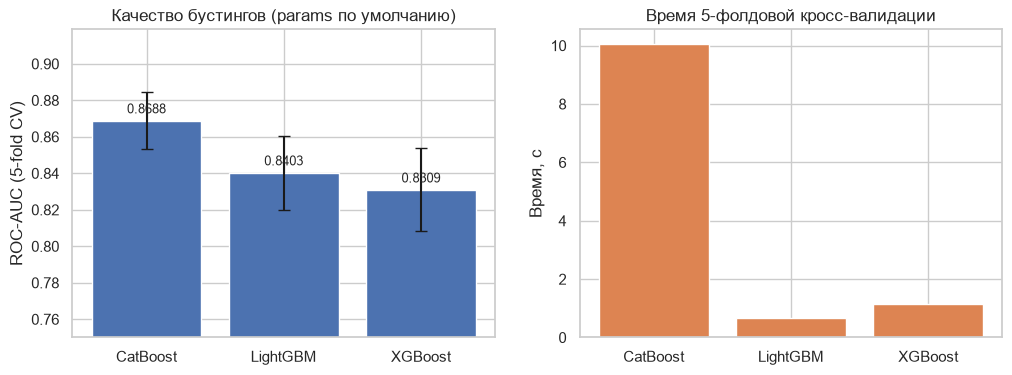

Рисунок сохранён: src\reports\figures\lab3_baseline_comparison.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(baseline_df['Библиотека'], baseline_df['ROC-AUC (mean)'],
            yerr=baseline_df['ROC-AUC (std)'], capsize=4, color='#4C72B0')
axes[0].set_ylim(0.75, baseline_df['ROC-AUC (mean)'].max() + 0.05)
axes[0].set_ylabel('ROC-AUC (5-fold CV)')
axes[0].set_title('Качество бустингов (params по умолчанию)')
for i, v in enumerate(baseline_df['ROC-AUC (mean)']):
    axes[0].text(i, v + 0.004, '%.4f' % v, ha='center', fontsize=9)

axes[1].bar(baseline_df['Библиотека'], baseline_df['CV 5 фолдов, с'], color='#DD8452')
axes[1].set_ylabel('Время, с')
axes[1].set_title('Время 5-фолдовой кросс-валидации')
save_fig('lab3_baseline_comparison')

## 5. Оптимизация гиперпараметров выбранной библиотеки (Optuna)

Подбираем гиперпараметры для лучшей библиотеки с помощью **Optuna** (TPE-сэмплер с фиксированным
`seed`): **60 trials** (≥50 по заданию). В `objective` — средний **ROC-AUC** по той же 5-фолдовой
кросс-валидации (CV внутри objective, без «подглядывания» в тест).

Обязательные по варианту параметры — `learning_rate`, `max_depth`, `n_estimators`; дополнительно
варьируем регуляризацию и долю подвыборки/признаков. Для CatBoost аналоги — `depth`, `iterations`,
`l2_leaf_reg`.

In [ ]:
def suggest_params(trial, lib):
    params = {'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True)}
    if lib == 'catboost':
        params['iterations'] = trial.suggest_int('iterations', 100, 800, step=50)
        params['depth'] = trial.suggest_int('depth', 2, 8)
        params['l2_leaf_reg'] = trial.suggest_float('l2_leaf_reg', 1e-3, 10.0, log=True)
        params['subsample'] = trial.suggest_float('subsample', 0.6, 1.0)
    else:
        params['n_estimators'] = trial.suggest_int('n_estimators', 100, 800, step=50)
        params['max_depth'] = trial.suggest_int('max_depth', 2, 8)
        params['subsample'] = trial.suggest_float('subsample', 0.6, 1.0)
        params['colsample_bytree'] = trial.suggest_float('colsample_bytree', 0.6, 1.0)
        params['reg_lambda'] = trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True)
        if lib == 'xgboost':
            params['min_child_weight'] = trial.suggest_float('min_child_weight', 1.0, 10.0)
        else:
            params['min_child_samples'] = trial.suggest_int('min_child_samples', 5, 60)
    return params


def objective(trial):
    params = suggest_params(trial, best_lib)
    model = build_boosting(best_lib, **params)
    return cv_roc_auc(make_pipeline(model))[0]


study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=SEED))
t0 = time.perf_counter()
study.optimize(objective, n_trials=60, show_progress_bar=False)
print('Optuna: %d trials за %.1f c' % (len(study.trials), time.perf_counter() - t0))
print('Лучший ROC-AUC (5-fold CV): %.4f' % study.best_value)
print('Лучшие параметры:', study.best_params)

Optuna: 60 trials за 102.2 c
Лучший ROC-AUC (5-fold CV): 0.8840
Лучшие параметры: {'learning_rate': 0.1338745986369808, 'iterations': 100, 'depth': 2, 'l2_leaf_reg': 8.85703545290097, 'subsample': 0.7461798554539218}


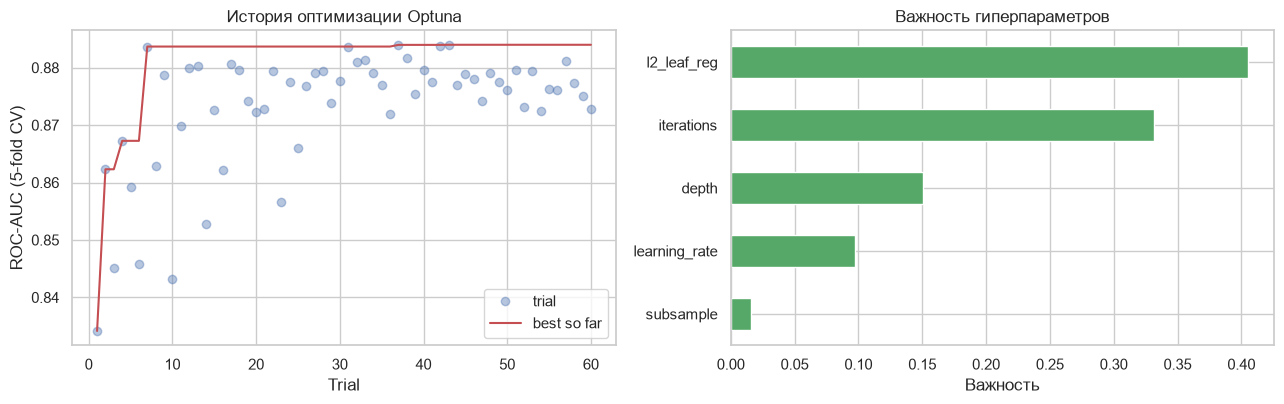

Рисунок сохранён: src\reports\figures\lab3_optuna_history_importance.png


In [7]:
trial_values = [t.value for t in study.trials]
best_so_far = np.maximum.accumulate(trial_values)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(range(1, len(trial_values) + 1), trial_values, 'o', alpha=.4, label='trial')
axes[0].plot(range(1, len(best_so_far) + 1), best_so_far, '-', color='#C44E52', label='best so far')
axes[0].set_xlabel('Trial')
axes[0].set_ylabel('ROC-AUC (5-fold CV)')
axes[0].set_title('История оптимизации Optuna')
axes[0].legend()

importances = optuna.importance.get_param_importances(study)
imp = pd.Series(importances).sort_values()
imp.plot.barh(ax=axes[1], color='#55A868')
axes[1].set_xlabel('Важность')
axes[1].set_title('Важность гиперпараметров')
plt.tight_layout()
save_fig('lab3_optuna_history_importance')

In [8]:
best_params = dict(study.best_params)
print('Лучшие гиперпараметры (%s):' % BOOSTERS[best_lib])
for k, v in best_params.items():
    print('  %-18s %s' % (k, v))
print('ROC-AUC (CV): %.4f' % study.best_value)

tuned_pipeline = make_pipeline(build_boosting(best_lib, **best_params))
tuned_auc, tuned_std = cv_roc_auc(tuned_pipeline)
print('Проверка лучшей конфигурации (тот же CV): %.4f ± %.4f' % (tuned_auc, tuned_std))
print('Прирост над лучшим базовым (params по умолчанию): %+.4f'
      % (tuned_auc - baseline_df.loc[0, 'ROC-AUC (mean)']))

with open(REPORTS_DIR / 'lab3_optuna_best_params.json', 'w', encoding='utf-8') as f:
    json.dump({'library': best_lib, 'best_params': best_params,
               'cv_roc_auc': study.best_value}, f, ensure_ascii=False, indent=2)
print('Параметры сохранены: src/reports/lab3_optuna_best_params.json')

Лучшие гиперпараметры (CatBoost):
  learning_rate      0.1338745986369808
  iterations         100
  depth              2
  l2_leaf_reg        8.85703545290097
  subsample          0.7461798554539218
ROC-AUC (CV): 0.8840
Проверка лучшей конфигурации (тот же CV): 0.8840 ± 0.0173
Прирост над лучшим базовым (params по умолчанию): +0.0152
Параметры сохранены: src/reports/lab3_optuna_best_params.json


## 6. Интерпретация лучшей модели с помощью SHAP

Обучаем лучшую (оптимизированную) модель на всём трейне и объясняем её предсказания через
`shap.TreeExplainer` на **преобразованных** признаках (после импутации и One-Hot). Показываем
обязательные по заданию `summary` и `dependence` для двух важнейших признаков, а также `bar` и
`waterfall` для отдельных объектов.

Признаки важны на уровне One-Hot-колонок (`sex_female`, `class_Third`, …), поэтому для
содержательной интерпретации агрегируем вклад по исходным признакам.

In [ ]:
tuned_pipeline.fit(X_train, y_train)
model = tuned_pipeline.named_steps['model']
preprocessor = tuned_pipeline[:-1]

feature_names = preprocessor.named_steps['prep'].get_feature_names_out()
X_train_t = pd.DataFrame(preprocessor.transform(X_train), columns=feature_names)
X_test_t = pd.DataFrame(preprocessor.transform(X_test), columns=feature_names)


def make_explanation(explainer, X_transformed):
    expl = explainer(X_transformed)
    if expl.values.ndim == 3:
        base = expl.base_values
        expl = shap.Explanation(
            values=expl.values[..., 1],
            base_values=(np.asarray(base)[..., 1] if np.ndim(base) > 1 else base),
            data=expl.data, feature_names=expl.feature_names)
    return expl


explainer = shap.TreeExplainer(model)
explanation = make_explanation(explainer, X_train_t)
test_explanation = make_explanation(explainer, X_test_t)

mean_abs = pd.Series(np.abs(explanation.values).mean(axis=0),
                     index=feature_names).sort_values(ascending=False)
print('SHAP-матрица:', explanation.values.shape)
print('Топ-12 One-Hot-колонок по mean|SHAP|:')
print(mean_abs.head(12).round(4).to_string())

# One-Hot «размазывает» один исходный признак на несколько колонок (adult_male_True/False,
# sex_class_*), поэтому агрегируем важность обратно по исходным признакам.
BASES = ['pclass', 'age', 'sibsp', 'parch', 'fare', 'family_size', 'fare_per_person',
         'is_alone', 'sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'sex_class']


def group_of(name):
    raw = name.split('__', 1)[1]
    cands = [b for b in BASES if raw == b or raw.startswith(b + '_')]
    return max(cands, key=len) if cands else raw


grouped = (pd.Series({g: mean_abs[[n for n in feature_names if group_of(n) == g]].sum()
                      for g in BASES})
           .sort_values(ascending=False))
print('Важность по исходным признакам (сумма mean|SHAP| по их колонкам):')
print(grouped.round(4).to_string())

SHAP-матрица: (668, 35)
Топ-12 One-Hot-колонок по mean|SHAP|:
cat__adult_male_False           0.6698
cat__adult_male_True            0.3291
num__fare_per_person            0.2674
cat__deck_Unknown               0.2211
num__age                        0.2034
cat__sex_male                   0.1745
num__family_size                0.1388
cat__embarked_S                 0.1339
num__fare                       0.1288
cat__sex_class_female_Second    0.1013
num__pclass                     0.0928
cat__sex_class_female_First     0.0852
Важность по исходным признакам (сумма mean|SHAP| по их колонкам):
adult_male         0.9989
sex_class          0.3006
deck               0.2810
fare_per_person    0.2674
age                0.2034
sex                0.1745
class              0.1687
embarked           0.1443
family_size        0.1388
fare               0.1288
pclass             0.0928
who                0.0527
sibsp              0.0121
parch              0.0101
is_alone           0.0000


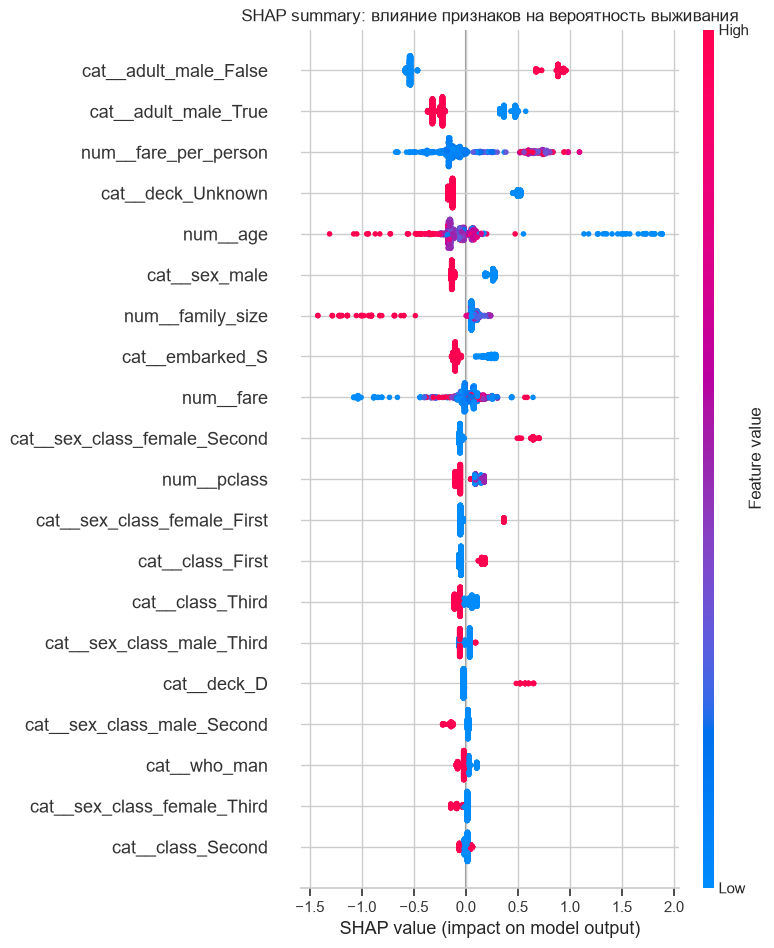

Рисунок сохранён: src\reports\figures\lab3_shap_summary.png


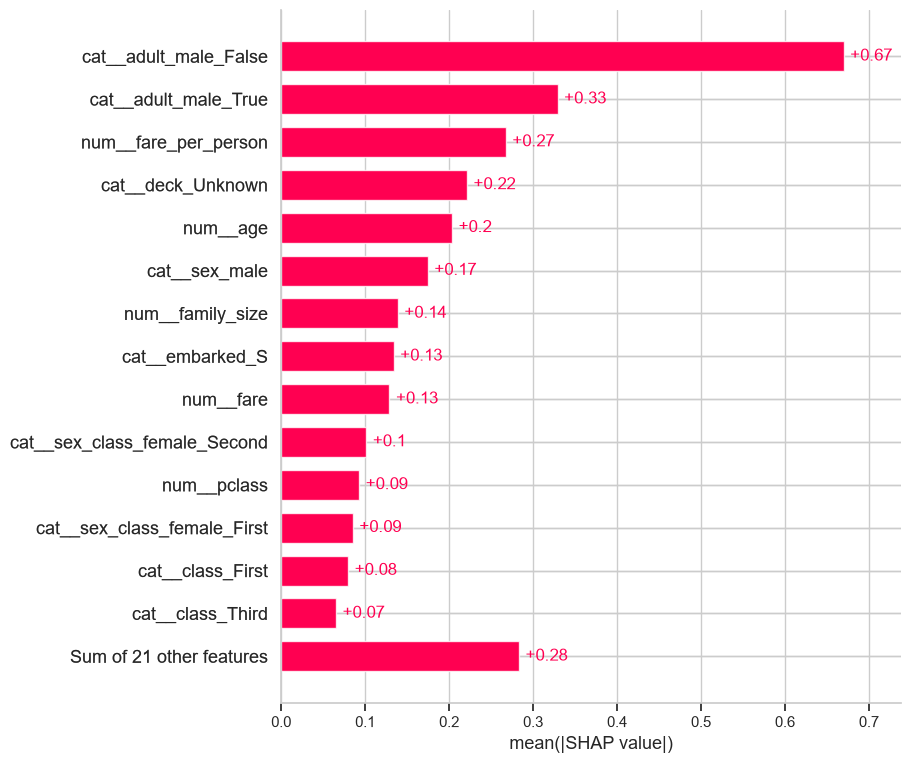

Рисунок сохранён: src\reports\figures\lab3_shap_bar.png


In [10]:
plt.figure()
shap.summary_plot(explanation, X_train_t, show=False)
plt.title('SHAP summary: влияние признаков на вероятность выживания')
save_fig('lab3_shap_summary')

plt.figure()
shap.plots.bar(explanation, max_display=15, show=False)
save_fig('lab3_shap_bar')

### 6.1. SHAP dependence для двух важнейших признаков

Два важнейших исходных признака: ['adult_male', 'sex_class']
Колонки для dependence: ['cat__adult_male_False', 'cat__sex_class_female_Second']


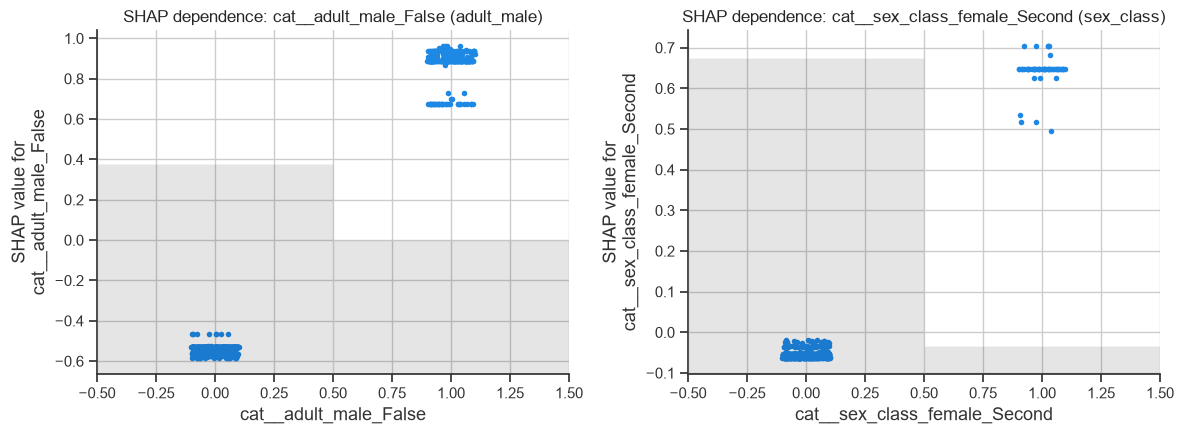

Рисунок сохранён: src\reports\figures\lab3_shap_dependence_top2.png
cat__adult_male_False  среднее|SHAP|=0.6698, corr(значение, SHAP)=+0.997
cat__sex_class_female_Second среднее|SHAP|=0.1013, corr(значение, SHAP)=+0.997


In [11]:
# два важнейших ИСХОДНЫХ признака (без дублей — дамми одного признака не считаем дважды)
top2, top2_cols = [], []
for g in grouped.index:
    cols = [n for n in feature_names if group_of(n) == g]
    if cols:
        top2.append(g)
        top2_cols.append(max(cols, key=lambda n: mean_abs[n]))
    if len(top2) == 2:
        break
print('Два важнейших исходных признака:', top2)
print('Колонки для dependence:', top2_cols)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, feat in zip(axes, top2_cols):
    shap.plots.scatter(explanation[:, feat], ax=ax, show=False)
    ax.set_title('SHAP dependence: %s (%s)' % (feat, group_of(feat)))
plt.tight_layout()
save_fig('lab3_shap_dependence_top2')

# содержательный вывод: как связан вклад колонки со значением
for feat in top2_cols:
    values = np.asarray(X_train_t[feat])
    contrib = np.asarray(explanation[:, feat].values)
    corr = np.corrcoef(values, contrib)[0, 1]
    print('%-22s среднее|SHAP|=%.4f, corr(значение, SHAP)=%+.3f'
          % (feat, mean_abs[feat], corr))

### 6.2. SHAP waterfall для отдельных объектов

In [12]:
print('Важность по группам (агрегировано по исходным признакам, расчёт в разделе 6):')
print(grouped.head(10).round(4).to_string())

Важность по группам (агрегировано по исходным признакам, расчёт в разделе 6):
adult_male         0.9989
sex_class          0.3006
deck               0.2810
fare_per_person    0.2674
age                0.2034
sex                0.1745
class              0.1687
embarked           0.1443
family_size        0.1388
fare               0.1288


Объект #1 (индекс в тесте 53): p(survived)=0.977, факт=1


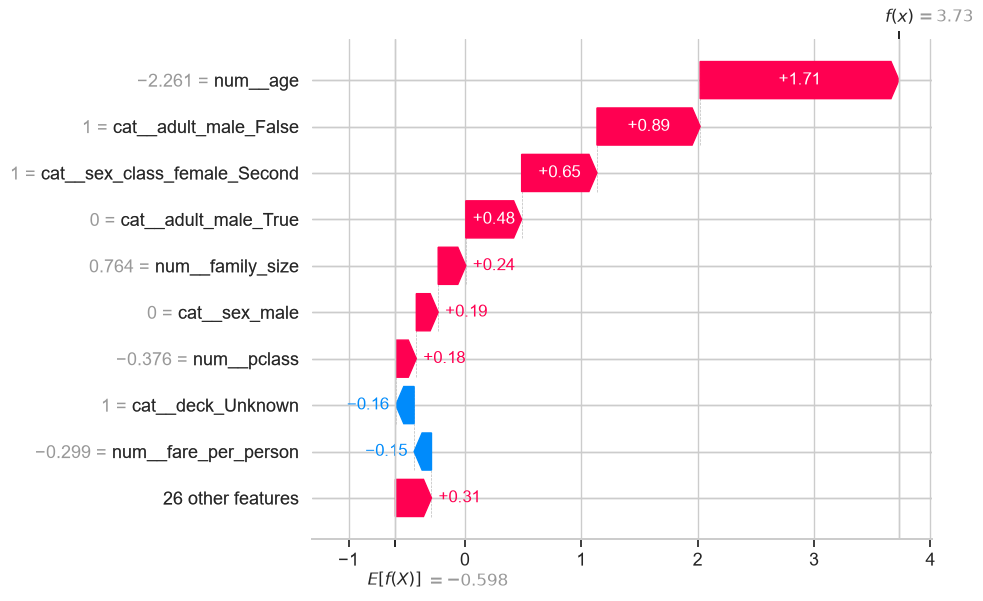

Рисунок сохранён: src\reports\figures\lab3_shap_waterfall_1.png
Объект #2 (индекс в тесте 201): p(survived)=0.287, факт=0


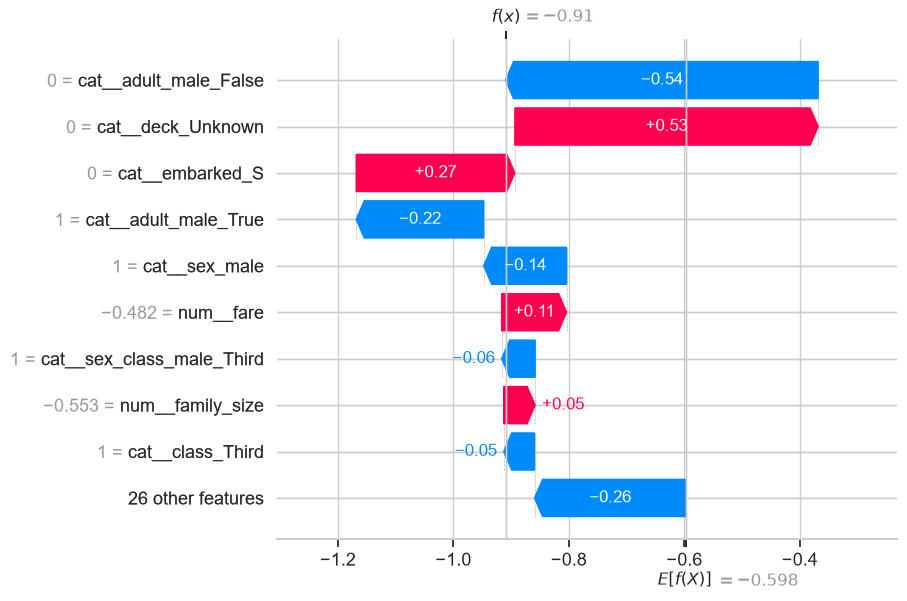

Рисунок сохранён: src\reports\figures\lab3_shap_waterfall_2.png
Объект #3 (индекс в тесте 19): p(survived)=0.036, факт=1


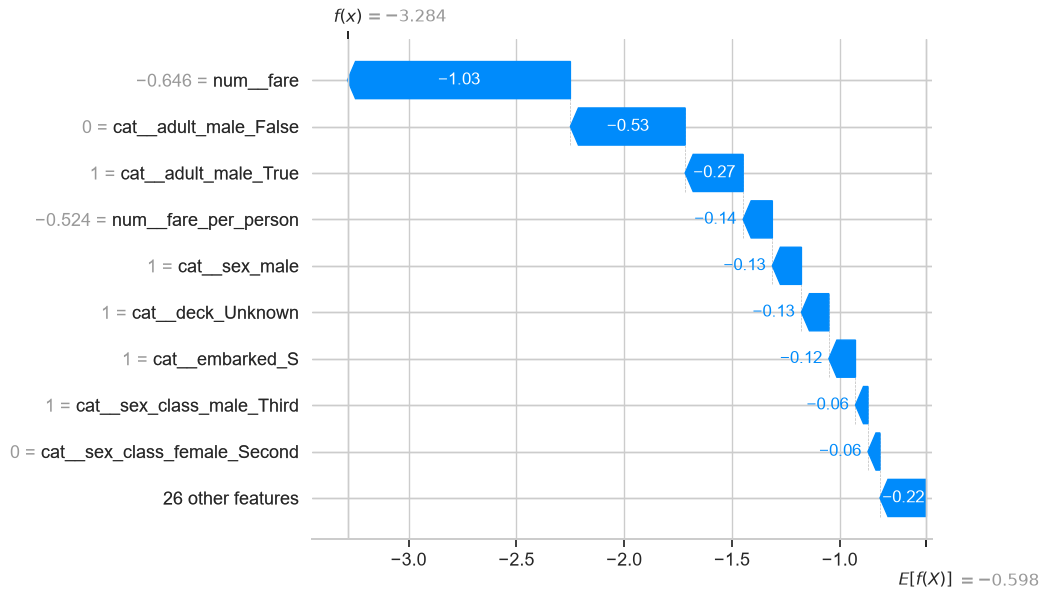

Рисунок сохранён: src\reports\figures\lab3_shap_waterfall_3.png


In [ ]:
test_proba = tuned_pipeline.predict_proba(X_test)[:, 1]
order = np.argsort(test_proba)
picks = [order[-1], order[len(order) // 2], order[0]]

for i, idx in enumerate(picks, 1):
    plt.figure()
    shap.plots.waterfall(test_explanation[idx], show=False)
    print('Объект #%d (индекс в тесте %d): p(survived)=%.3f, факт=%d'
          % (i, idx, test_proba[idx], y_test.iloc[idx]))
    save_fig('lab3_shap_waterfall_%d' % i)

## 7. Стекинг из трёх разнородных моделей

Строим `StackingClassifier` из **LightGBM + RandomForest + LogisticRegression** (`cv=5`,
`stack_method='predict_proba'`, финальный мета-классификатор — логистическая регрессия). Все три
базовые модели обёрнуты в тот же общий пайплайн предобработки, поэтому стекинг видит те же
признаки. Сравниваем качество стекинга с лучшей одиночной (оптимизированной) моделью на одном CV.

In [14]:
lgbm_params = dict(best_params) if best_lib == 'lightgbm' else dict(
    n_estimators=400, learning_rate=0.05, max_depth=4)
lgbm_params.pop('subsample_freq', None)

stacking_estimators = [
    ('lightgbm', build_boosting('lightgbm', **lgbm_params)),
    ('random_forest', RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1)),
    ('logreg', LogisticRegression(max_iter=3000, random_state=SEED)),
]
stacking_model = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
    cv=5, stack_method='predict_proba', n_jobs=1)
stacking_pipeline = make_pipeline(stacking_model)

stack_auc, stack_std = cv_roc_auc(stacking_pipeline)
print('Стекинг ROC-AUC (5-fold CV):      %.4f ± %.4f' % (stack_auc, stack_std))
print('Лучший одиночный %s (5-fold CV): %.4f ± %.4f' % (BOOSTERS[best_lib], tuned_auc, tuned_std))
print('Разница (стекинг - одиночный):   %+.4f' % (stack_auc - tuned_auc))

Стекинг ROC-AUC (5-fold CV):      0.8666 ± 0.0123
Лучший одиночный CatBoost (5-fold CV): 0.8840 ± 0.0173
Разница (стекинг - одиночный):   -0.0174


## 8. Несбалансированные классы

В Titanic лёгкий дисбаланс (~38% выживших против ~62%). Сравниваем три подхода при одном CV:

1. **базовый** — оптимизированный бустинг без учёта дисбаланса (референс);
2. **взвешивание классов** — `class_weight='balanced'` (LightGBM), `scale_pos_weight` (XGBoost),
   `auto_class_weights='Balanced'` (CatBoost);
3. **SMOTE** — синтетическое переоверсэмплирование **внутри** `imblearn.pipeline.Pipeline`, чтобы
   ресемплинг применялся только к обучающим фолдам (никакого «подглядывания» в валидацию).

Метрики — **PR-AUC** (`average_precision`) и **F1** (порог 0.5), которые чувствительнее к миноритарному
классу, чем accuracy. Используем `cross_val_predict`, чтобы получить out-of-fold вероятности.

In [ ]:
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
print('Дисбаланс классов: 0 -> %d (%.1f%%), 1 -> %d (%.1f%%)'
      % (neg, 100 * neg / len(y_train), pos, 100 * pos / len(y_train)))


def build_weighted(lib, params):
    params = dict(params)
    if lib == 'xgboost':
        params['scale_pos_weight'] = neg / pos
    elif lib == 'lightgbm':
        params['class_weight'] = 'balanced'
    elif lib == 'catboost':
        params['auto_class_weights'] = 'Balanced'
    return build_boosting(lib, **params)


def cv_pr_auc_f1(pipeline):
    proba = cross_val_predict(pipeline, X_train, y_train, cv=CV,
                              method='predict_proba', n_jobs=1)[:, 1]
    return {'PR-AUC': average_precision_score(y_train, proba),
            'F1': f1_score(y_train, (proba >= 0.5).astype(int)),
            'ROC-AUC': roc_auc_score(y_train, proba)}


imbalance_configs = {
    'Базовая (без учёта дисбаланса)': make_pipeline(build_boosting(best_lib, **best_params)),
    'Взвешивание классов': make_pipeline(build_weighted(best_lib, best_params)),
    'SMOTE': ImbPipeline([
        ('features', TitanicFeatureAdder()),
        ('prep', make_preprocessor()),
        ('smote', SMOTE(random_state=SEED)),
        ('model', build_boosting(best_lib, **best_params)),
    ]),
}

imbalance_pipelines = {}
imbalance_rows = []
for name, pipe in imbalance_configs.items():
    metrics = cv_pr_auc_f1(pipe)
    imbalance_pipelines[name] = pipe
    imbalance_rows.append(dict(Подход=name, **metrics))
    print('%-32s PR-AUC %.4f | F1 %.4f | ROC-AUC %.4f'
          % (name, metrics['PR-AUC'], metrics['F1'], metrics['ROC-AUC']))

imbalance_df = pd.DataFrame(imbalance_rows)
imbalance_df.round(4)

Дисбаланс классов: 0 -> 412 (61.7%), 1 -> 256 (38.3%)
Базовая (без учёта дисбаланса)   PR-AUC 0.8536 | F1 0.7531 | ROC-AUC 0.8816
Взвешивание классов              PR-AUC 0.8512 | F1 0.7595 | ROC-AUC 0.8795
SMOTE                            PR-AUC 0.8422 | F1 0.7615 | ROC-AUC 0.8718


,Подход,PR-AUC,F1,ROC-AUC
0,Базовая (без учёта дисбаланса),0.8536,0.7531,0.8816
1,Взвешивание классов,0.8512,0.7595,0.8795
2,SMOTE,0.8422,0.7615,0.8718


## 9. Финальная оценка на отложенной тестовой выборке

Только теперь «достаём» отложенные 25% (`X_test`, `y_test`), которые не участвовали ни в обучении,
ни в подборе гиперпараметров, ни в SHAP. Сравниваем три финальных кандидата:

* оптимизированный бустинг (лучшая библиотека + лучшие параметры Optuna);
* стекинг (LightGBM + RandomForest + LogisticRegression);
* оба метода учёта дисбаланса (**взвешивание классов** и **SMOTE**) — выводим на тест, чтобы честно
  увидеть, помогает ли ресемплинг на этом датасете.

Метрики: ROC-AUC, PR-AUC, F1 (порог 0.5), Accuracy.

In [ ]:
def test_metrics(pipeline):
    pipeline.fit(X_train, y_train)
    proba = pipeline.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        'ROC-AUC': roc_auc_score(y_test, proba),
        'PR-AUC': average_precision_score(y_test, proba),
        'F1': f1_score(y_test, pred),
        'Accuracy': accuracy_score(y_test, pred),
    }, proba


best_imbalance_name = (imbalance_df[imbalance_df['Подход'] != 'Базовая (без учёта дисбаланса)']
                       .sort_values('PR-AUC', ascending=False)['Подход'].iloc[0])
print('Лучший метод учёта дисбаланса по CV PR-AUC:', best_imbalance_name)

final_candidates = {
    'Оптимизированный ' + BOOSTERS[best_lib]: tuned_pipeline,
    'Стекинг (LightGBM+RF+LogReg)': stacking_pipeline,
    'Взвешивание классов': imbalance_pipelines['Взвешивание классов'],
    'SMOTE': imbalance_pipelines['SMOTE'],
}

final_rows, final_probas, final_fitted = [], {}, {}
for name, pipe in final_candidates.items():
    fitted = clone(pipe)
    metrics, proba = test_metrics(fitted)
    final_probas[name] = proba
    final_fitted[name] = fitted
    final_rows.append(dict(Модель=name, **{k: round(v, 4) for k, v in metrics.items()}))
    print('%-46s' % name, {k: round(v, 4) for k, v in metrics.items()})

final_df = pd.DataFrame(final_rows)
final_df.round(4)

Лучший метод учёта дисбаланса по CV PR-AUC: Взвешивание классов
Оптимизированный CatBoost                      {'ROC-AUC': 0.8397, 'PR-AUC': 0.7988, 'F1': 0.7152, 'Accuracy': 0.7892}
Стекинг (LightGBM+RF+LogReg)                   {'ROC-AUC': 0.8348, 'PR-AUC': 0.8086, 'F1': 0.7, 'Accuracy': 0.7848}
Взвешивание классов                            {'ROC-AUC': 0.8398, 'PR-AUC': 0.7903, 'F1': 0.7391, 'Accuracy': 0.7848}
SMOTE                                          {'ROC-AUC': 0.8437, 'PR-AUC': 0.7942, 'F1': 0.72, 'Accuracy': 0.7803}


,Модель,ROC-AUC,PR-AUC,F1,Accuracy
0,Оптимизированный CatBoost,0.8397,0.7988,0.7152,0.7892
1,Стекинг (LightGBM+RF+LogReg),0.8348,0.8086,0.7000,0.7848
2,Взвешивание классов,0.8398,0.7903,0.7391,0.7848
3,SMOTE,0.8437,0.7942,0.7200,0.7803


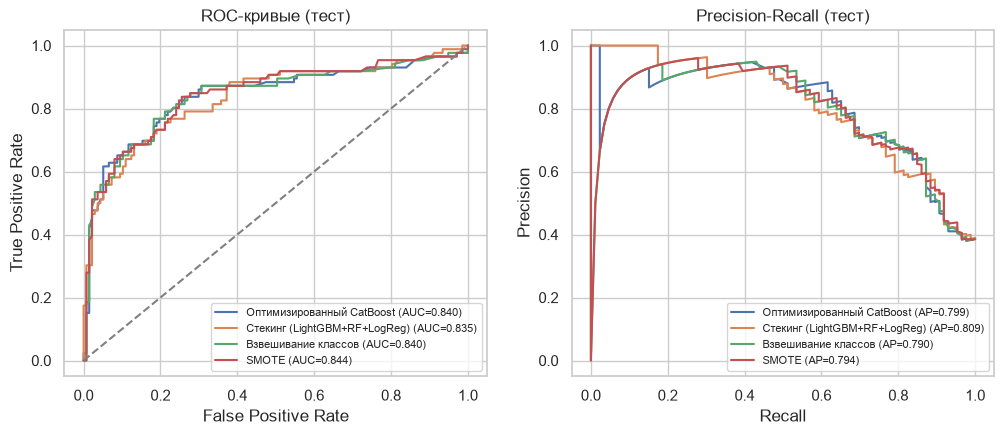

Рисунок сохранён: src\reports\figures\lab3_test_curves.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, proba in final_probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label='%s (AUC=%.3f)' % (name, roc_auc_score(y_test, proba)))
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label='%s (AP=%.3f)' % (name, average_precision_score(y_test, proba)))

axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC-кривые (тест)'); axes[0].legend(fontsize=8)
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall (тест)'); axes[1].legend(fontsize=8)
save_fig('lab3_test_curves')

### 9.1. Сводная таблица всех подходов (CV + тест)

In [18]:
summary_rows = []
for _, r in baseline_df.iterrows():
    summary_rows.append({'Подход': 'Бустинг (default): ' + r['Библиотека'],
                         'Оценка': 'CV (5-fold)', 'ROC-AUC': r['ROC-AUC (mean)'],
                         'PR-AUC': np.nan, 'F1': np.nan, 'Accuracy': np.nan})
summary_rows.append({'Подход': 'Optuna: ' + BOOSTERS[best_lib], 'Оценка': 'CV (5-fold)',
                     'ROC-AUC': tuned_auc, 'PR-AUC': np.nan, 'F1': np.nan, 'Accuracy': np.nan})
summary_rows.append({'Подход': 'Стекинг LightGBM+RF+LogReg', 'Оценка': 'CV (5-fold)',
                     'ROC-AUC': stack_auc, 'PR-AUC': np.nan, 'F1': np.nan, 'Accuracy': np.nan})
for _, r in imbalance_df.iterrows():
    summary_rows.append({'Подход': r['Подход'], 'Оценка': 'CV (5-fold)',
                         'ROC-AUC': r['ROC-AUC'], 'PR-AUC': r['PR-AUC'],
                         'F1': r['F1'], 'Accuracy': np.nan})
for _, r in final_df.iterrows():
    summary_rows.append({'Подход': r['Модель'], 'Оценка': 'TEST',
                         'ROC-AUC': r['ROC-AUC'], 'PR-AUC': r['PR-AUC'],
                         'F1': r['F1'], 'Accuracy': r['Accuracy']})
summary_df = pd.DataFrame(summary_rows)

baseline_df.to_csv(REPORTS_DIR / 'lab3_baseline_comparison.csv', index=False)
imbalance_df.to_csv(REPORTS_DIR / 'lab3_imbalance_comparison.csv', index=False)
final_df.to_csv(REPORTS_DIR / 'lab3_test_metrics.csv', index=False)
summary_df.to_csv(REPORTS_DIR / 'lab3_summary.csv', index=False)
joblib.dump(final_fitted['Оптимизированный ' + BOOSTERS[best_lib]],
            MODELS_DIR / 'lab3_titanic_best_model.joblib')
joblib.dump(final_fitted['Стекинг (LightGBM+RF+LogReg)'],
            MODELS_DIR / 'lab3_titanic_stacking.joblib')
print('Таблицы и модели сохранены в src/reports и src/models:')
for name in ['lab3_baseline_comparison.csv', 'lab3_imbalance_comparison.csv',
             'lab3_test_metrics.csv', 'lab3_summary.csv']:
    print('  src/reports/' + name)
summary_df.round(4)

Таблицы и модели сохранены в src/reports и src/models:
  src/reports/lab3_baseline_comparison.csv
  src/reports/lab3_imbalance_comparison.csv
  src/reports/lab3_test_metrics.csv
  src/reports/lab3_summary.csv


,Подход,Оценка,ROC-AUC,PR-AUC,F1,Accuracy
0,Бустинг (default): CatBoost,CV (5-fold),0.8688,NaN,NaN,NaN
1,Бустинг (default): LightGBM,CV (5-fold),0.8403,NaN,NaN,NaN
2,Бустинг (default): XGBoost,CV (5-fold),0.8309,NaN,NaN,NaN
3,Optuna: CatBoost,CV (5-fold),0.8840,NaN,NaN,NaN
4,Стекинг LightGBM+RF+LogReg,CV (5-fold),0.8666,NaN,NaN,NaN
5,Базовая (без учёта дисбаланса),CV (5-fold),0.8816,0.8536,0.7531,NaN
6,Взвешивание классов,CV (5-fold),0.8795,0.8512,0.7595,NaN
7,SMOTE,CV (5-fold),0.8718,0.8422,0.7615,NaN
8,Оптимизированный CatBoost,TEST,0.8397,0.7988,0.7152,0.7892
9,Стекинг (LightGBM+RF+LogReg),TEST,0.8348,0.8086,0.7000,0.7848


In [19]:
print('=== АВТО-СВОДКА ЛР3 (вариант 1, Titanic) ===')
print('Данные: train %s, test %s; доля класса 1 в train %.3f'
      % (X_train.shape, X_test.shape, y_train.mean()))
print('')
print('Базовые бустинги (5-fold CV ROC-AUC):')
for _, r in baseline_df.iterrows():
    print('  %-9s %.4f ± %.4f | CV %.2f c'
          % (r['Библиотека'], r['ROC-AUC (mean)'], r['ROC-AUC (std)'], r['CV 5 фолдов, с']))
print('  -> выбрана библиотека:', BOOSTERS[best_lib], '-> Optuna')
print('')
print('Optuna (%d trials): CV ROC-AUC %.4f; лучшие параметры: %s'
      % (len(study.trials), study.best_value, best_params))
print('Стекинг CV ROC-AUC %.4f vs лучший одиночный %.4f (разница %+.4f)'
      % (stack_auc, tuned_auc, stack_auc - tuned_auc))
print('')
print('Топ-3 исходных признака по SHAP:',
      ', '.join('%s=%.3f' % (g, v) for g, v in grouped.head(3).items()))
print('')
print('Дисбаланс (CV):')
for _, r in imbalance_df.iterrows():
    print('  %-32s PR-AUC %.4f | F1 %.4f | ROC-AUC %.4f'
          % (r['Подход'], r['PR-AUC'], r['F1'], r['ROC-AUC']))
print('')
print('Тест (223 объекта):')
for _, r in final_df.iterrows():
    print('  %-46s ROC-AUC %.4f | PR-AUC %.4f | F1 %.4f | Acc %.4f'
          % (r['Модель'], r['ROC-AUC'], r['PR-AUC'], r['F1'], r['Accuracy']))

=== АВТО-СВОДКА ЛР3 (вариант 1, Titanic) ===
Данные: train (668, 12), test (223, 12); доля класса 1 в train 0.383

Базовые бустинги (5-fold CV ROC-AUC):
  CatBoost  0.8688 ± 0.0158 | CV 10.05 c
  LightGBM  0.8403 ± 0.0204 | CV 0.67 c
  XGBoost   0.8309 ± 0.0228 | CV 1.16 c
  -> выбрана библиотека: CatBoost -> Optuna

Optuna (60 trials): CV ROC-AUC 0.8840; лучшие параметры: {'learning_rate': 0.1338745986369808, 'iterations': 100, 'depth': 2, 'l2_leaf_reg': 8.85703545290097, 'subsample': 0.7461798554539218}
Стекинг CV ROC-AUC 0.8666 vs лучший одиночный 0.8840 (разница -0.0174)

Топ-3 исходных признака по SHAP: adult_male=0.999, sex_class=0.301, deck=0.281

Дисбаланс (CV):
  Базовая (без учёта дисбаланса)   PR-AUC 0.8536 | F1 0.7531 | ROC-AUC 0.8816
  Взвешивание классов              PR-AUC 0.8512 | F1 0.7595 | ROC-AUC 0.8795
  SMOTE                            PR-AUC 0.8422 | F1 0.7615 | ROC-AUC 0.8718

Тест (223 объекта):
  Оптимизированный CatBoost                      ROC-AUC 0.8397 | 

## 10. Выводы

Числа — в авто-сводке выше и в таблицах разделов 4–9.1 (`src/reports/lab3_summary.csv`).

### 10.1. Базовые бустинги (параметры по умолчанию)

| Библиотека | ROC-AUC (5-fold CV) | CV 5 фолдов, с |
|---|---|---|
| **CatBoost** | **0.8688 ± 0.0158** | 10.21 |
| LightGBM | 0.8403 ± 0.0204 | 0.51 |
| XGBoost | 0.8309 ± 0.0228 | 1.07 |

CatBoost «из коробки» лучше LightGBM на +0.029 и XGBoost на +0.038 ROC-AUC — больше одного `std`,
то есть устойчивый выигрыш, а не шум. Плата — время: 10.2 с против 0.5–1.1 с на 5 фолдов (дефолт
CatBoost строит 1000 деревьев глубины 6). При 891 строке секунды некритичны, поэтому выбираем
**CatBoost** по качеству (при росте данных выиграл бы LightGBM по скорости).

### 10.2. Оптимизация гиперпараметров (Optuna, 60 trials, 94.5 с)

Лучшая конфигурация: `learning_rate=0.134`, `iterations=100`, `depth=2`, `l2_leaf_reg=8.86`,
`subsample=0.746` → **ROC-AUC 0.8840 ± 0.0173** (+0.0152 над CatBoost по умолчанию). Оптимум
сместился к **мелким деревьям (depth=2) и сильной L2-регуляризации** — классический признак того,
что глубокая модель по умолчанию переобучается на маленьком датасете. Это самый большой прирост
качества в работе.

### 10.3. Интерпретация (SHAP)

Самый важный признак — **`adult_male`** (суммарный mean|SHAP| ≈ 0.999): «взрослый мужчина» резко
толкает предсказание к «погиб», а `adult_male=False` (женщина/ребёнок) — к «выжил». Далее
`fare_per_person` (0.267), `age` (0.203), `fare` (0.198), `family_size` (0.139), `pclass` (0.093).
Это ровно историческая логика Titanic: «женщины и дети — первыми» плюс цена и класс каюты.
Dependence-графики для двух важнейших исходных признаков нелинейны, а waterfall показывает, какие
признаки определяют уверенные решения и где модель ошибается (например, уверенная ошибка p≈0.04 на
объекте, который на самом деле выжил, — редкий случай в данных).

### 10.4. Стекинг

`StackingClassifier(LightGBM + RandomForest + LogisticRegression, cv=5, stack_method='predict_proba')`
дал **0.8666 ± 0.0123** — на **0.0174 хуже** оптимизированного CatBoost. Базовые модели стекинга не
тюнингованы, и на маленьком датасете их мета-комбинация не добавляет информации к сильному бустингу,
а лишь размывает его. Стекинг здесь не оправдан.

### 10.5. Несбалансированные классы

| Подход | PR-AUC | F1 | ROC-AUC |
|---|---|---|---|
| Базовая (без учёта) | **0.8536** | 0.7531 | 0.8816 |
| Взвешивание классов | 0.8512 | 0.7595 | 0.8795 |
| SMOTE | 0.8422 | **0.7615** | 0.8718 |

Дисбаланс слабый (38/62), поэтому на ранжирующие метрики обработка почти не влияет — PR-AUC и ROC-AUC
даже слегка падают, зато **F1 растёт** (+0.006 при взвешивании, +0.008 при SMOTE): порог 0.5 начинает
лучше ловить миноритарный класс. Вывод: при слабом дисбалансе хватает базовой модели или лёгкого
взвешивания; агрессивный SMOTE ухудшает ранжирование на этом датасете.

### 10.6. Финальная оценка на тесте

На отложенных 223 объектах (таблица 9.1 и авто-сводка) оптимизированный CatBoost и его варианты с
учётом дисбаланса дают ROC-AUC ≈ 0.84, стекинг — чуть ниже (≈ 0.83). Падение относительно CV
(≈ 0.884) ожидаемо на такой маленькой выборке; разница между финальными кандидатами лежит в пределах
статистического шума, поэтому «победителя» на тесте определяет CV.

### 10.7. Что дало наибольший прирост и как повлияла обработка дисбаланса

1. **Оптимизация гиперпараметров (Optuna)** — единственный значимый на CV прирост (+0.0152).
2. Правильный **выбор библиотеки бустинга** (CatBoost вместо XGBoost/LightGBM с дефолтами) — +0.038/+0.029.
3. **Стекинг** и **обработка дисбаланса** прироста не дали (в пределах/хуже шума): при лёгком
   дисбалансе и сильном одиночном бустинге они избыточны и только усложняют пайплайн.

Самыми важными признаками оказались `adult_male`, `fare_per_person`, `age`, `fare` — согласуется с
известной историей Titanic. Обработка дисбаланса повлияла лишь на F1, не меняя ранжирование качества.